In [40]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
%matplotlib qt

file_path = "ensemble_de_donnees/eau/lkq_eau.edf"
raw_eeg = mne.io.read_raw_edf(file_path, preload=True)

Extracting EDF parameters from ensemble_de_donnees/eau/lkq_eau.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 13439  =      0.000 ...   104.992 secs...


In [41]:
eeg_channels = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1", "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
raw_eeg.pick(eeg_channels)

montage = mne.channels.make_standard_montage("standard_1020")
raw_eeg.set_montage(montage)

<RawEDF | lkq_eau.edf, 14 x 13440 (105.0 s), ~1.5 MiB, data loaded>

Channels marked as bad:
none


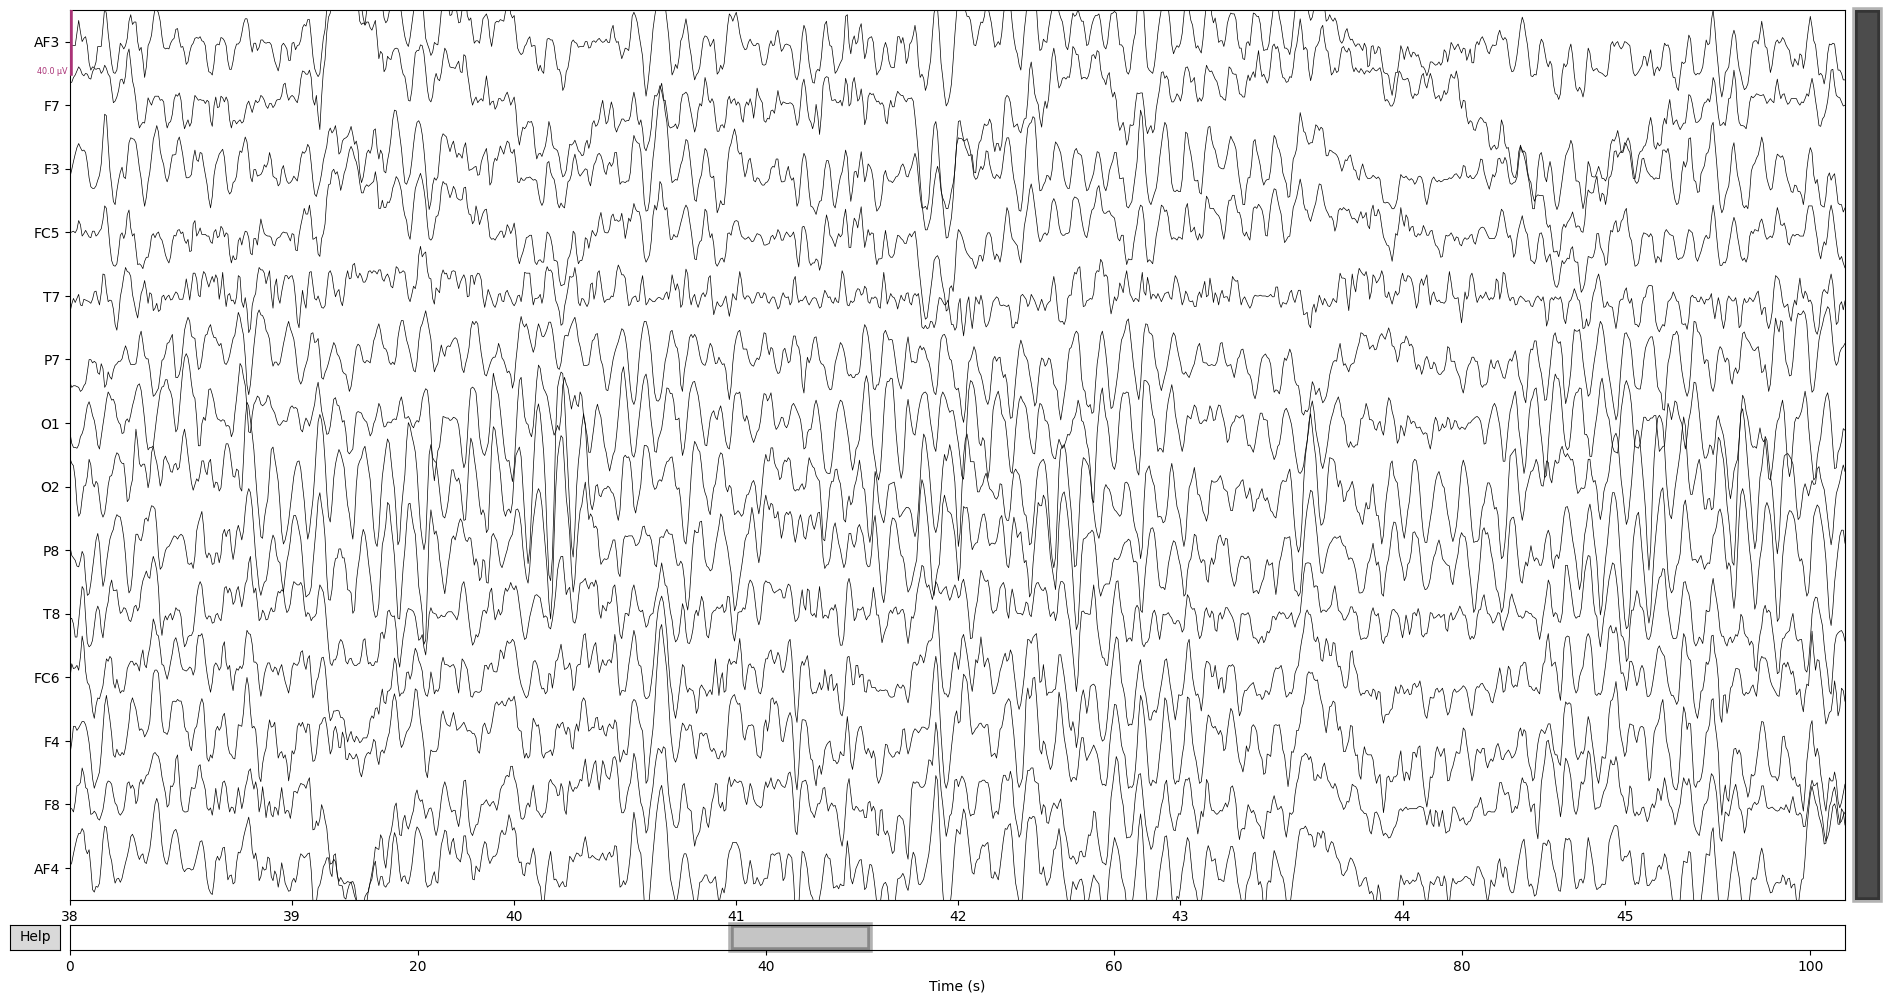

In [22]:
raw_eeg.plot(block=True, duration=8)

### Preprocessing

##### Trim Data

In [23]:
eyes_opened = raw_eeg.copy().crop(tmin=0, tmax=5)
eyes_closed = raw_eeg.copy().crop(tmin=15)
raw_cut = mne.concatenate_raws([eyes_opened, eyes_closed])

##### Bandpass Filter

Channels marked as bad:
none


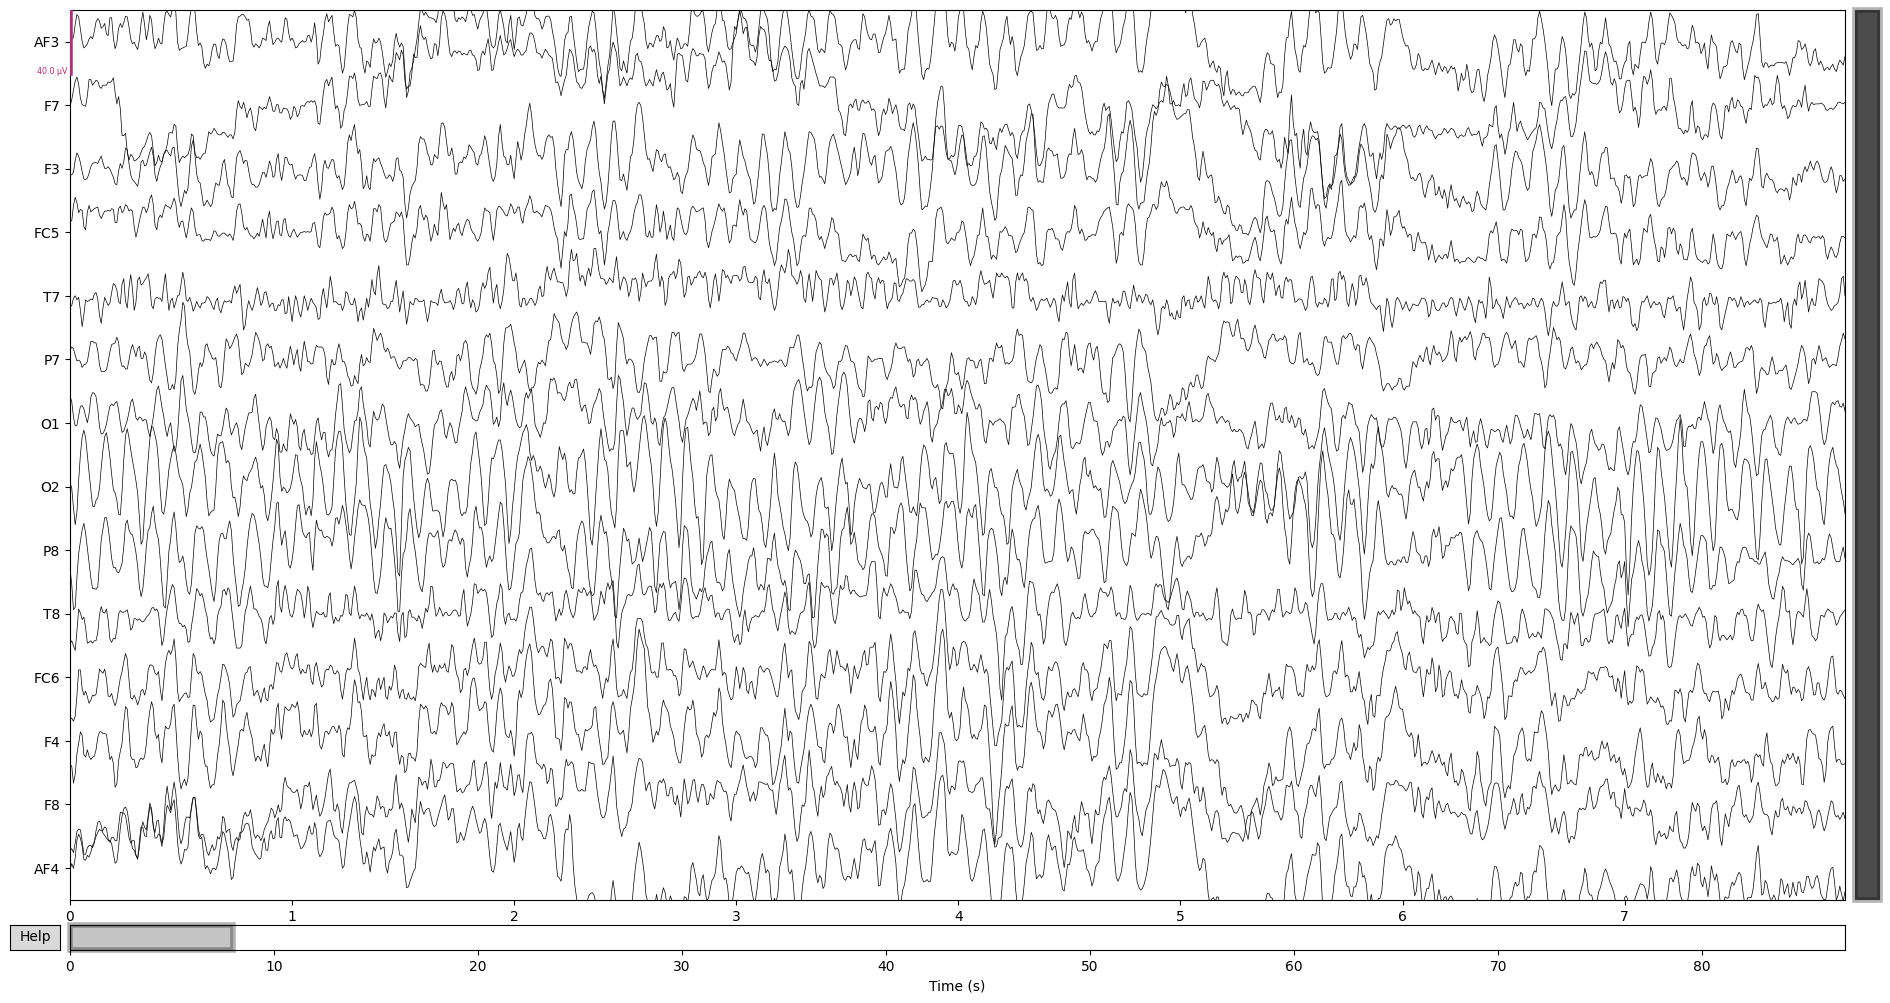

In [24]:
eyes_closed.plot(block=True, duration=8)

In [25]:
raw_filtered = eyes_closed.copy().filter(l_freq=1.0, h_freq=45.0, fir_design="firwin")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 423 samples (3.305 s)



##### Independent Component Analysis (ICA)

In [26]:
ica = mne.preprocessing.ICA(n_components=14, random_state=42)
ica.fit(raw_filtered)

Fitting ICA to data using 14 channels (please be patient, this may take a while)
Selecting by number: 14 components
Fitting ICA took 0.1s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,22 iterations on raw data (11136 samples)
ICA components,14
Available PCA components,14
Channel types,eeg
ICA components marked for exclusion,—


In [27]:
eog_indices, eog_scores = ica.find_bads_eog(raw_filtered, ch_name=['F7', 'F8'])
print(f"Found EOG artifacts in components: {eog_indices}")
ica.exclude = eog_indices

Using EOG channels: F7, F8
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 1280 samples (10.000 s)

... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz

In [28]:
muscle_indices, muscle_scores = ica.find_bads_muscle(raw_filtered)
print(f"Found muscle artifacts in components: {muscle_indices}")
ica.exclude = muscle_indices

Effective window size : 16.000 (s)
Found muscle artifacts in components: [3, 5, 6, 10, 11, 13]


In [29]:
raw_clean = ica.apply(raw_filtered.copy())

Applying ICA to Raw instance
    Transforming to ICA space (14 components)
    Zeroing out 6 ICA components
    Projecting back using 14 PCA components


##### Epoching and Artifact Rejection

In [30]:
# Epoch 4 seconds of data with 2 seconds overlap
events = mne.make_fixed_length_events(raw_clean, duration=4.0, overlap=2.0)
epochs = mne.Epochs(raw_clean, events, tmin=0, tmax=4.0, baseline=None, preload=True)

Not setting metadata
42 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 42 events and 513 original time points ...
0 bad epochs dropped


In [ ]:
reject_criteria = 120e-6  # 100 µV
max_bad_channels_allowed = 3

clean_epochs = []

for i in range(len(epochs)):
    epoch = epochs[i].get_data()[0]
    ptp_amplitude = np.ptp(epoch, axis=1)  # Peak-to-peak amplitude for each channel
    
    bad_ch_idx = np.where(ptp_amplitude > reject_criteria)[0]
    bad_channels = [epochs.ch_names[idx] for idx in bad_ch_idx]
    
    if len(bad_channels) == 0:
        clean_epochs.append(epochs[i].copy())
        
    elif len(bad_channels) <= max_bad_channels_allowed:
        print(f"Epoch {i} has bad channels: {bad_channels}")
        temp_epoch = epochs[i].copy()
        temp_epoch.info["bads"] = bad_channels
        temp_epoch.interpolate_bads(reset_bads=True) # Interpolate bad channels with good channels
        
        clean_epochs.append(temp_epoch)
    
    else:
        print(f"Epoch {i} has too many bad channels: {bad_channels}. Discarding this epoch.")
    
    
if len(clean_epochs) > 0:
    clean_epochs = mne.concatenate_epochs(clean_epochs)
    print(f"Number of original epochs: {len(epochs)}")
    print(f"Number of remaining clean epochs: {len(clean_epochs)}")
    
else:
    print("No clean epochs remaining after artifact rejection.")

Epoch 1 has bad channels: ['F4']
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 94.1 mm
Computing interpolation matrix from 13 sensor positions
Interpolating 1 sensors
Epoch 2 has bad channels: ['F4']
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 94.1 mm
Computing interpolation matrix from 13 sensor positions
Interpolating 1 sensors
Epoch 11 has bad channels: ['O2', 'P8']
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 94.1 mm
Computing interpolation matrix from 12 sensor positions
Interpolating 2 sensors
Epoch 12 has bad channels: ['O2', 'P8']
Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 94.1 mm
Computing interpolation matrix from 12 sensor positions
Interpolating 

Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none


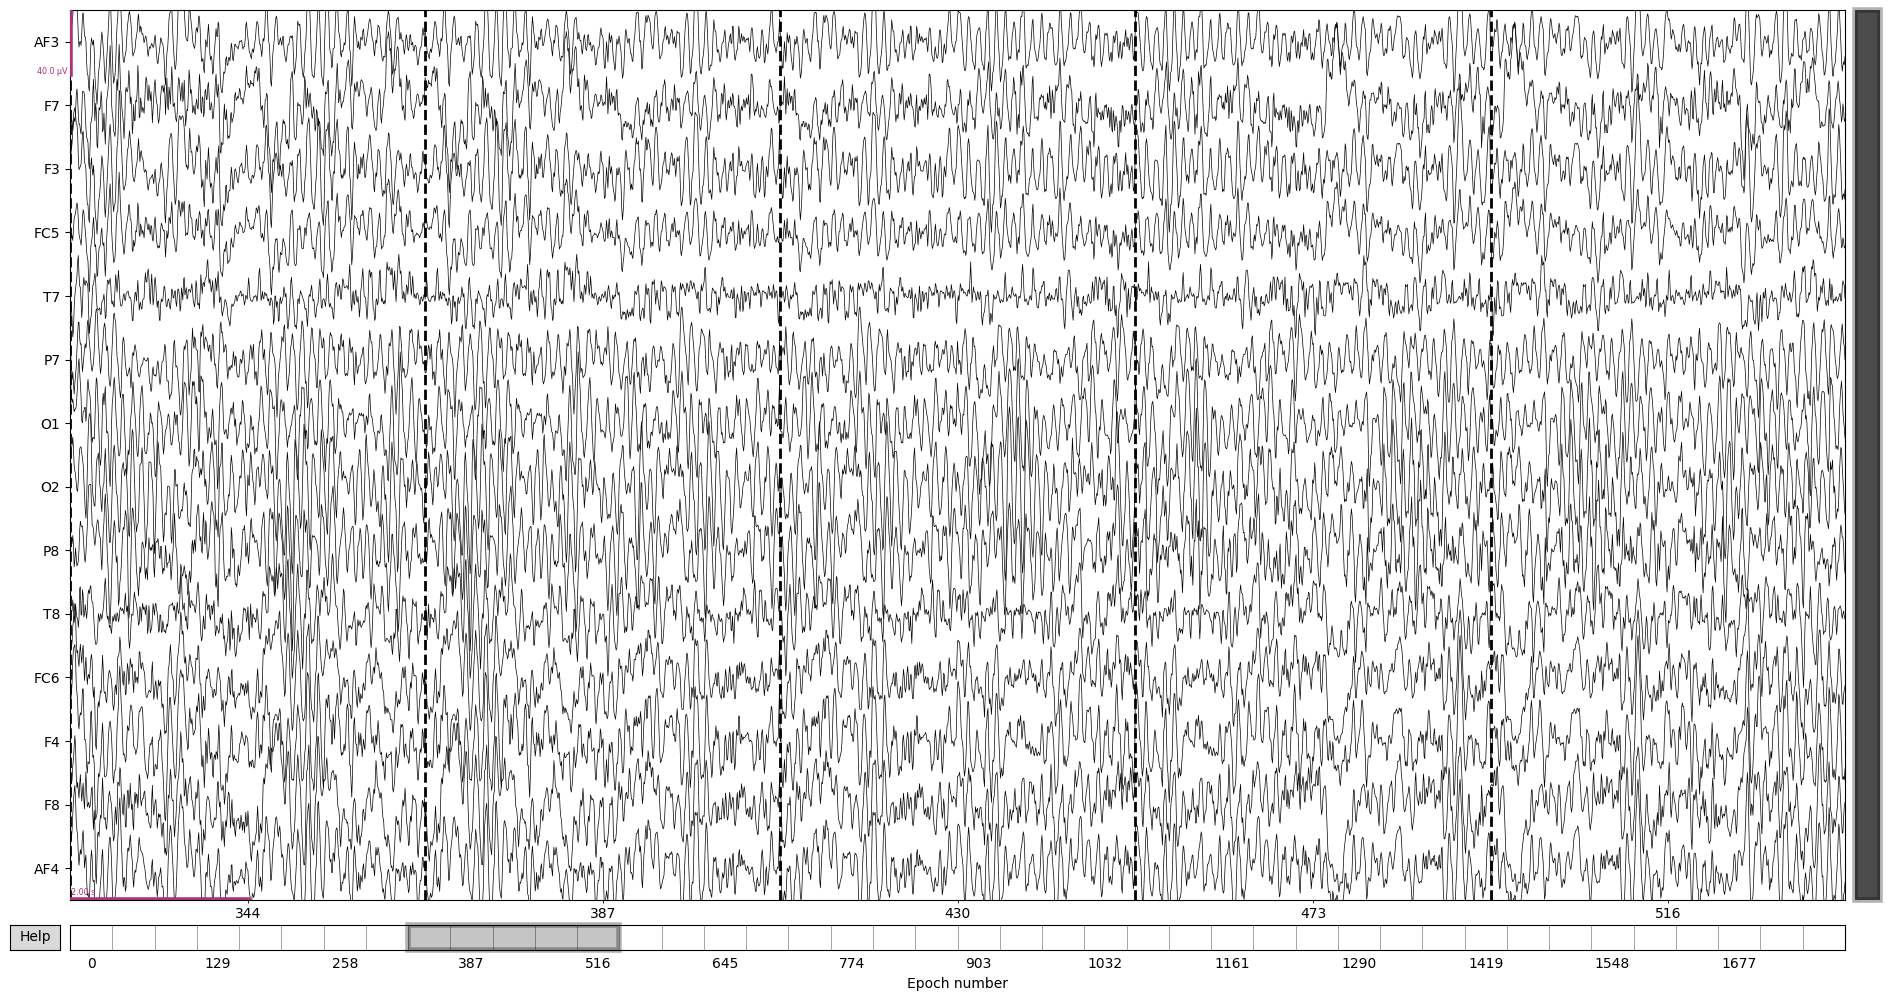

In [32]:
clean_epochs.plot(block=True, n_epochs=5, n_channels=14)

#### Power Spectral Density with Welch's Method using FFT

In [ ]:
spectrum = clean_epochs.compute_psd(method="welch", fmin=1, fmax=45, n_fft=256, n_overlap=128)
psds, freqs = spectrum.get_data(return_freqs=True)

Effective window size : 2.000 (s)


In [34]:
def get_band_power(psds, freqs, band):
    # Check if the specified frequency band is valid
    if len(band) != 2 or band[0] >= band[1]:
        raise ValueError(f"Invalid frequency band {band}. It should be a tuple of (low_freq, high_freq) with low_freq < high_freq.")
    elif band[0] < freqs[0] or band[1] > freqs[-1]:
        raise ValueError(f"Frequency band {band} is out of range. Valid range is {freqs[0]}-{freqs[-1]} Hz.")
    
    # Extract the average power in the specified frequency band
    band_idx = np.logical_and(freqs >= band[0], freqs <= band[1])
    band_power = np.mean(psds[:, :, band_idx], axis=2)
    return band_power

##### Extract power from all epochs

In [35]:
theta_band = (4, 8)
alpha_band = (8, 13)
beta_band = (13, 30)

theta_power = get_band_power(psds, freqs, theta_band)
alpha_power = get_band_power(psds, freqs, alpha_band)
beta_power = get_band_power(psds, freqs, beta_band)

#### Calculate Metrics using Different Frequency Bands

In [36]:
ch_names = clean_epochs.ch_names

# Channels for happiness
f3_idx = ch_names.index('F3')
f4_idx = ch_names.index('F4')

# Channels for calmness
calmness_channels = ['O1', 'O2']
calmness_idx = [ch_names.index(ch) for ch in calmness_channels]


faa_per_epoch = np.log(alpha_power[:, f4_idx] + 1e-12) - np.log(alpha_power[:, f3_idx] + 1e-12)

avg_alpha_calm = np.mean(alpha_power[:, calmness_idx], axis=1)
avg_beta_calm = np.mean(beta_power[:, calmness_idx], axis=1)
calmness_per_epoch = avg_alpha_calm / (avg_beta_calm + 1e-12)

final_faa = np.mean(faa_per_epoch)
final_calmness = np.mean(calmness_per_epoch)

print(f"Total Clean Epochs Used : {len(clean_epochs)}")
print(f"Happiness Score         : {final_faa:.4f}")
print(f"Calmness Index          : {final_calmness:.4f}")

Total Clean Epochs Used : 42
Happiness Score         : 0.0534
Calmness Index          : 13.3271
